In [53]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


from sklearn.datasets import fetch_california_housing


print("Libraries loaded successfully")

Libraries loaded successfully


In [ ]:
# obtains the dataset
# returns data in pandas-friendly format
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset shape:", df.shape)
# displays first 5 rows
display(df.head(5))

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Understand the columns
print(df.columns) # displays all columns names in Dataframe
print(df.info())  # Identifies the data type of row & columns
print(df.describe()) # 

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744  

In [24]:
# Explore the data (EDA)
print("Missing Values")
print(df.isnull().sum())

print("Duplicate rows: " , df.duplicated().sum())

Missing Values
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Duplicate rows:  0


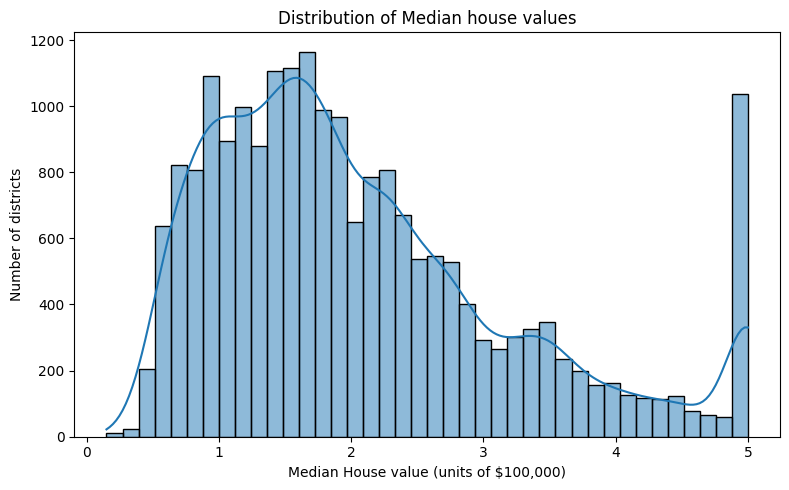

In [ ]:
# Plotting the target distribution
# Histogram
plt.figure(figsize = (8, 5))
sns.histplot(df["MedHouseVal"], bins = 40, kde = True)

plt.title("Distribution of Median house values")
plt.xlabel("Median House value (units of $100,000)")
plt.ylabel("Number of districts")

plt.tight_layout()
plt.show()

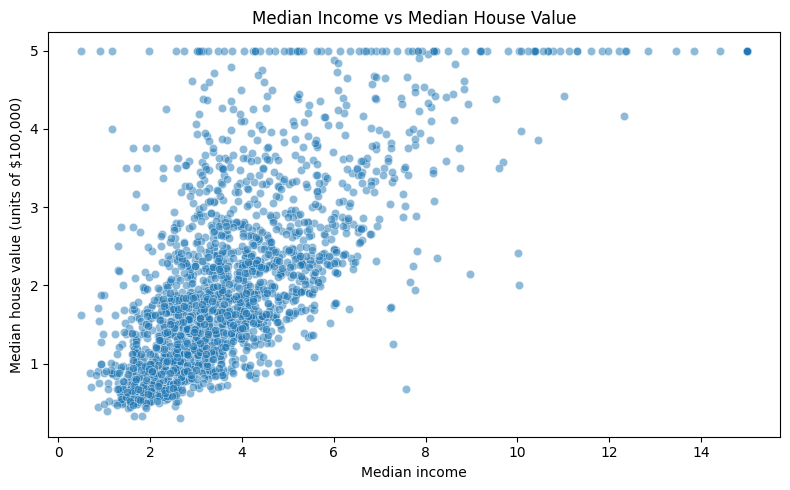

In [ ]:
# Scatterplot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data = df.sample(2000, random_state=42),
    x = "MedInc",
    y = "MedHouseVal",
    alpha = 0.5
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median income")
plt.ylabel("Median house value (units of $100,000)")

plt.tight_layout()
plt.show()

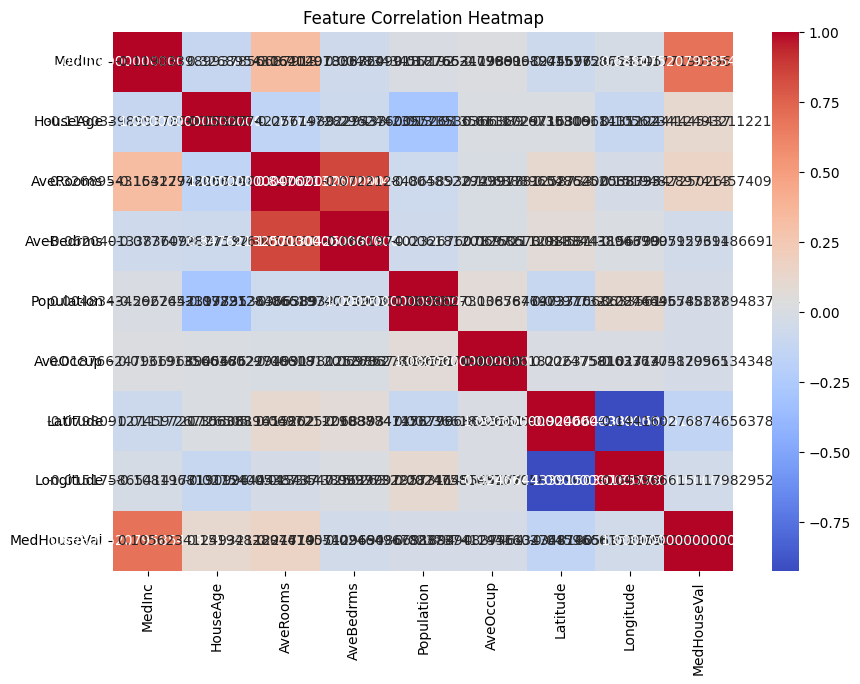

In [46]:
# Heatmap
plt.figure(figsize = (10, 7))

sns.heatmap(
    df.corr(numeric_only = True),
    annot = True,
    cmap = "coolwarm",
    fmt = ".21f"
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout
plt.show()

In [ ]:
# Separate features (X) and target (y)
X = df.drop(columns = ["MedHouseVal"])
y = df["MedHouseVal"]

print("Features Shape: ", X.shape)
print("Target Shape: ", y.shape)


Features Shape:  (20640, 8)
Target Shape:  (20640,)


In [ ]:
# Split the dataset into training and testing data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42
)
print("Training rows: ", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows:  16512
Testing rows:  4128


In [ ]:
# Train two machine learning models 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

linear_model = LinearRegression()

random_forest_model = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42,
    n_jobs = -1
)
linear_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both Models trained successfully")

Both Models trained successfully


In [50]:
# Make predictions
linear_predictions = linear_model.predict(X_test)

forest_predictions = random_forest_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Linear Regression": linear_predictions,
    "Random Forest": forest_predictions
})

display(comparison.head(10))

/Users/rohanyadav2112/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rohanyadav2112/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/rohanyadav2112/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,Actual,Linear Regression,Random Forest
0,0.47700,0.719123,0.508710
1,0.45800,1.764017,0.744040
2,5.00001,2.709659,4.915087
3,2.18600,2.838926,2.527520
4,2.78000,2.604657,2.265550
5,1.58700,2.011754,1.652130
6,1.98200,2.645500,2.345860
7,1.57500,2.168755,1.662580
8,3.40000,2.740746,2.716220
9,4.46600,3.915615,4.923589


In [55]:
# Evaluate Model Performance
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE ($)": mae * 100_000,
        "RMSE ($)": rmse * 100_000,
        "R2 Score": r2
    }

results = pd.DataFrame([
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        forest_predictions
    )
])

display(results.round(3))
    

,Model,MAE ($),RMSE ($),R2 Score
0,Linear Regression,53320.013,74558.138,0.576
1,Random Forest,32759.935,50569.357,0.805


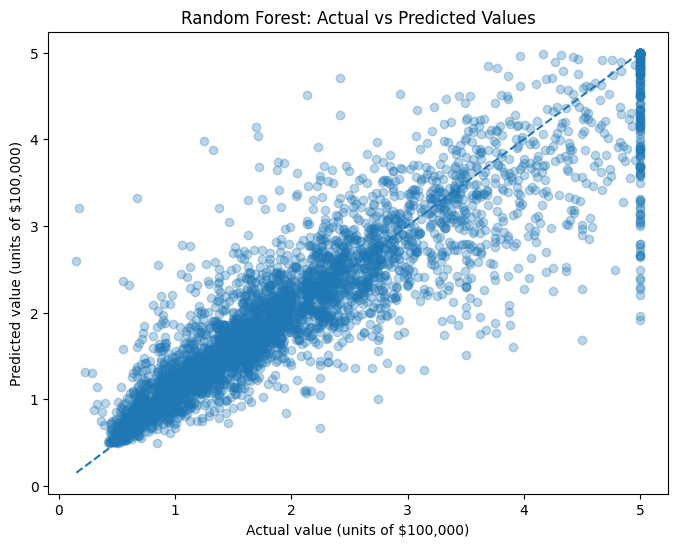

In [62]:
# Plot actual vs predicted values
plt.figure(figsize = (8, 6))
plt.scatter(
    y_test,
    forest_predictions,
    alpha = 0.3
)

minmum = min(y_test.min(), forest_predictions.min())
maximum = max(y_test.max(), forest_predictions.max())

plt.plot(
    [minmum, maximum],
    [minmum, maximum],
    linestyle = "--"
)
plt.xlabel("Actual value (units of $100,000)")
plt.ylabel("Predicted value (units of $100,000)")
plt.title("Random Forest: Actual vs Predicted Values")

plt.tight_layout
plt.show()

,Feature,Importance
0,MedInc,0.525037
5,AveOccup,0.138564
6,Latitude,0.088855
7,Longitude,0.088669
1,HouseAge,0.054558
2,AveRooms,0.044195
4,Population,0.030503
3,AveBedrms,0.029620


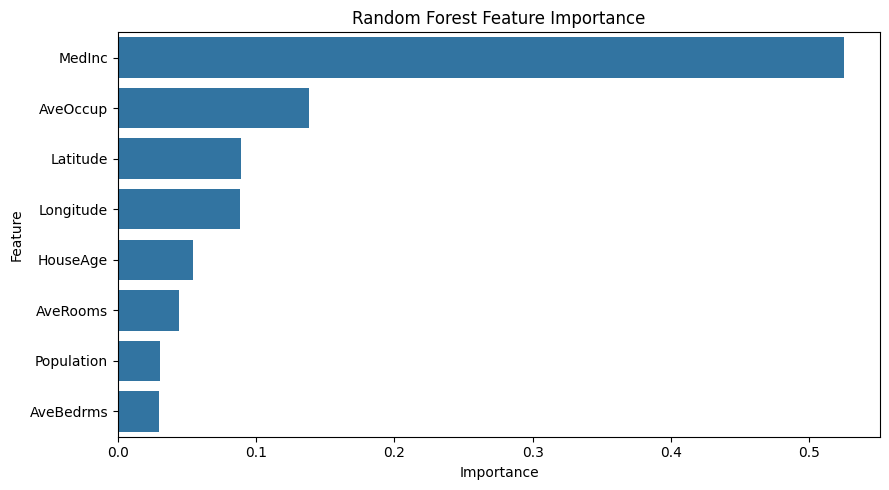

In [63]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values("Importance", ascending = False)

display(importance)
plt.figure(figsize = (9, 5))

sns.barplot(
    data = importance,
    x = "Importance",
    y = "Feature"
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [66]:
# Predict the price
new_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 20.0,
    "AveRooms": 5.5,
    "AveBedrms": 1.1,
    "Population": 1000.0,
    "AveOccup": 3.0,
    "Latitude": 34.05,
    "Longitude": -118.25
}])

predicted_value = random_forest_model.predict(new_house)[0]
print("Predicted value: ${predicted_value * 100,000:,.0f}")

Predicted value: ${predicted_value * 100,000:,.0f}


In [67]:
# Save your trained model
import joblib

joblib.dump(
    random_forest_model,
    "house_price_model.joblib"
)
print("Model Saved successfully")

Model Saved successfully


In [ ]:
loaded_model = joblib.load("house_price_model.joblib")

prediction = loaded_model.predict(new_house)[0]

print(f"Predicted value: ${prediction * 100_000:,.0f}")